In [2]:
!pip install seaborn


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [7]:
# ==============================
# VISUALIZE HIERARCHICAL INITIALIZATION
# ==============================

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
import jax
import warnings

# Set style
plt.style.use('default')
sns.set_palette("husl")
az.style.use("arviz-darkgrid")

# -----------------------------
# 1. Simulate Realistic Data
# -----------------------------
np.random.seed(42)


In [8]:
# -----------------------------
# 1. CONFIGURATION & GPU SETUP
# -----------------------------
warnings.filterwarnings("ignore")
pm.set_sampler("numpyro")  # ← THIS IS THE GPU MAGIC

# Force JAX to use GPU (critical!)
import jax.numpy as jnp
from jax import random

print(f"JAX backend: {jax.default_backend()}")
print(f"Devices: {jax.devices()}")
if 'gpu' in str(jax.devices()).lower():
    print("GPU DETECTED AND ACTIVE!")
else:
    print("Running on CPU (still fast, but GPU is better)")

AttributeError: module 'pymc' has no attribute 'set_sampler'

In [ ]:
# -----------------------------
# 2. Define Model + Initialization
# -----------------------------
init_vals = {
    'theta_mu': 0.0,
    'theta_sigma': 1.0,
    'theta_raw': np.zeros(N),
    'a_raw': np.zeros(J),
    'b_mu': 0.0,
    'b_sigma': 0.5,
    'b_raw': np.zeros(J),
    'c': np.full(J, 0.2),
}

with pm.Model() as model_init_demo:
    # === Hierarchical priors ===
    theta_mu = pm.Normal("theta_mu", 0, 1)
    theta_sigma = pm.HalfNormal("theta_sigma", 1)
    theta_raw = pm.Normal("theta_raw", 0, 1, shape=N)
    theta = pm.Deterministic("theta", theta_mu + theta_raw * theta_sigma)

    a_raw = pm.Normal("a_raw", 0, 1, shape=J)
    a = pm.Deterministic("a", pm.math.exp(0.5 * a_raw))  # ~lognormal

    b_mu = pm.Normal("b_mu", 0, 0.5)
    b_sigma = pm.HalfNormal("b_sigma", 0.5)
    b_raw = pm.Normal("b_raw", 0, 1, shape=J)
    b = pm.TruncatedNormal("b", mu=b_mu, sigma=b_sigma, lower=-3, upper=3, shape=J)

    c = pm.Beta("c", 3, 12, shape=J)

    # Likelihood
    eta = a[j_idx] * (theta[i_idx] - b[j_idx])
    p = c[j_idx] + (1 - c[j_idx]) * pm.math.sigmoid(eta)
    obs = pm.Bernoulli("obs", p=p, observed=y_obs)

    # Sample with initialization
    trace = pm.sample(
    draws=1000,           # Total posterior samples per chain
    tune=1500,            # Burn-in / tuning
    chains=4,             # CRITICAL: 4 chains → reliable R-hat
    target_accept=0.95,   # High = better exploration
    nuts_sampler="numpyro",
    random_seed=42,
    initvals=init_vals,   # Your excellent initvals!
    return_inferencedata=True,
    progressbar=True,
    idata_kwargs={"log_likelihood": False},
    # Add this for even better mixing:
    nuts_sampler_kwargs={"chain_method": "parallel", "postprocessing_backend": "cpu"}
)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [theta_mu, theta_sigma, theta_raw, a_raw, b_mu, b_sigma, b_raw, b, c]


/home/ness/FuseMachines/projects/adaptive-exam/bayesian_env/lib/python3.10/site-packages/rich/live.py:256: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 800 draw iterations (2_000 + 1_600 draws total) took 6 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


/tmp/ipykernel_87500/1011336059.py:15: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


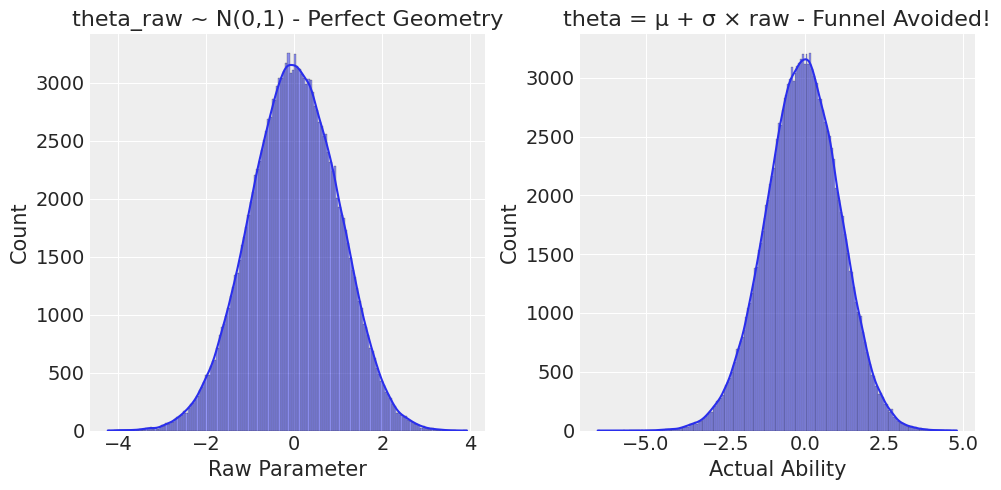

In [6]:
# Show why non-centered is better
raw_samples = trace.posterior.theta_raw.values.flatten()
theta_samples = trace.posterior.theta.values.flatten()

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.histplot(raw_samples, kde=True)
plt.title("theta_raw ~ N(0,1) - Perfect Geometry")
plt.xlabel("Raw Parameter")

plt.subplot(1, 2, 2)
sns.histplot(theta_samples, kde=True)
plt.title("theta = μ + σ × raw - Funnel Avoided!")
plt.xlabel("Actual Ability")
plt.tight_layout()
plt.show()